╔══════════════════════════════════════════════════════════════════════════╗
║  UMWM: Unified Multimodal World Model                                  ║
║  CSE 465 - Pattern Recognition & Neural Networks | Final Project       ║
║                                                                        ║
║  A single shared encoder-decoder architecture that processes 4          ║
║  modalities (image, audio, text, video) in a unified latent space,     ║
║  generates text from any modality, and predicts future world states.   ║
╚══════════════════════════════════════════════════════════════════════════╝

Run this notebook in Google Colab with a T4 GPU runtime.
Runtime → Change runtime type → T4 GPU

Copy-paste each section into separate Colab cells, or upload as .py and
run with: %run UMWM_Notebook.py


## SECTION 0: SETUP & INSTALLATION


In [1]:
import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

install("torch")
install("torchvision")
install("matplotlib")
install("scikit-learn")
install("tqdm")

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
import torchvision.transforms.functional as TF
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from tqdm.auto import tqdm
import random
import warnings
warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB")


Device: cuda
  GPU: Tesla T4
  VRAM: 15.6 GB


## SECTION 1: CONFIGURATION


In [2]:
class Config:
    IMG_SIZE        = 32
    IN_CHANNELS     = 3
    LATENT_DIM      = 128
    FEAT_DIM        = 512
    HIDDEN_DIM      = 256
    TEXT_EMBED_DIM  = 64
    NUM_CLASSES     = 10
    BATCH_SIZE      = 128
    LR              = 3e-4
    BETA_KL         = 0.5
    LAMBDA_CONTRAST = 1.0
    TEMPERATURE     = 0.07
    EPOCHS_PHASE1   = 30
    EPOCHS_PHASE2   = 20
    EPOCHS_PHASE3   = 20
    EPOCHS_PHASE4   = 15
    VIDEO_LEN       = 4
    MAX_TEXT_LEN    = 12
    PAD_IDX         = 0
    SOS_IDX         = 1
    EOS_IDX         = 2

cfg = Config()

CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

print(f"Config loaded. Latent dim={cfg.LATENT_DIM}, Batch={cfg.BATCH_SIZE}")


Config loaded. Latent dim=128, Batch=128


## SECTION 2: VOCABULARY & TEXT PROCESSING


In [3]:
TEMPLATES = [
    "a photo of a {}",
    "a {} in the wild",
    "an image of a {}",
    "a picture showing a {}",
    "this is a {}",
    "a small {} photograph",
    "a {} captured on camera",
    "looking at a {}",
    "a clear image of a {}",
    "a real world {}",
]

def build_vocab():
    words = set(["<pad>", "<sos>", "<eos>"])
    for cls in CLASS_NAMES:
        for tpl in TEMPLATES:
            for w in tpl.format(cls).split():
                words.add(w.lower())
    word2idx = {w: i for i, w in enumerate(sorted(words))}
    idx2word = {i: w for w, i in word2idx.items()}
    return word2idx, idx2word

WORD2IDX, IDX2WORD = build_vocab()
VOCAB_SIZE = len(WORD2IDX)
cfg.PAD_IDX = WORD2IDX["<pad>"]
cfg.SOS_IDX = WORD2IDX["<sos>"]
cfg.EOS_IDX = WORD2IDX["<eos>"]

def text_to_indices(text, max_len=cfg.MAX_TEXT_LEN):
    tokens = [cfg.SOS_IDX] + [WORD2IDX.get(w, 0) for w in text.lower().split()] + [cfg.EOS_IDX]
    tokens = tokens[:max_len]
    tokens += [cfg.PAD_IDX] * (max_len - len(tokens))
    return tokens

def indices_to_text(indices):
    words = []
    for idx in indices:
        w = IDX2WORD.get(idx, "")
        if w == "<eos>":
            break
        if w not in ("<pad>", "<sos>"):
            words.append(w)
    return " ".join(words)

print(f"Vocabulary built: {VOCAB_SIZE} words")


Vocabulary built: 35 words


## SECTION 3: SYNTHETIC AUDIO — CLASS-SPECIFIC SPECTROGRAMS


AudioGenerator ready


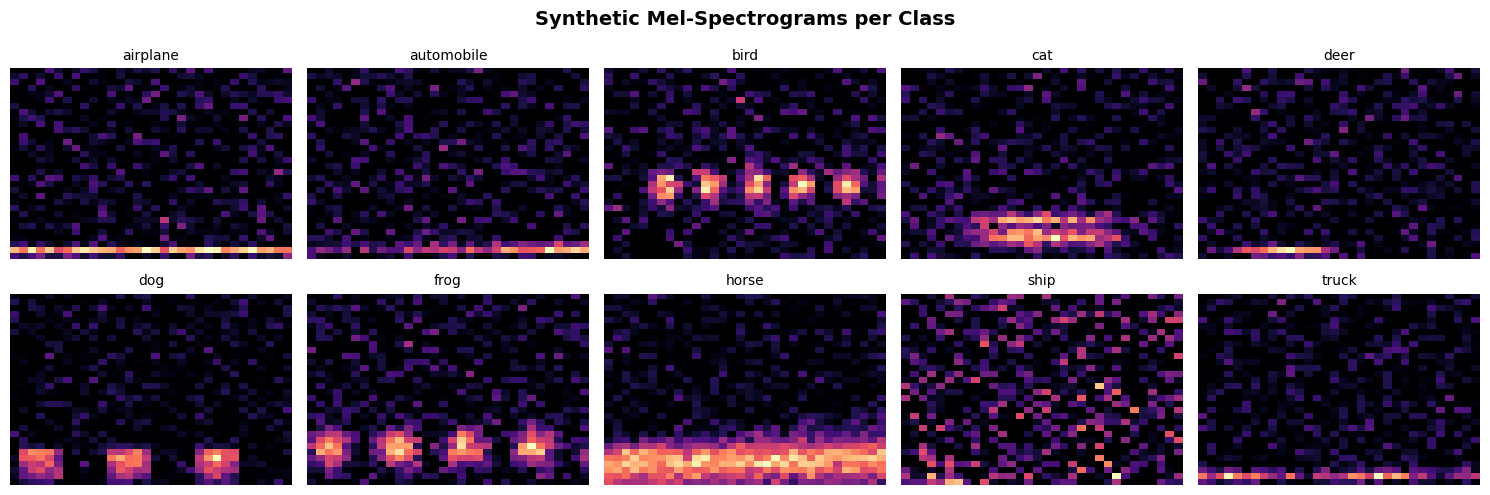

In [4]:
class AudioGenerator:
    """
    Generates synthetic mel-spectrograms with class-specific acoustic signatures,
    with per-sample randomization of the underlying acoustic parameters (not just
    pixel noise) so the task carries real intra-class variance instead of being a
    deterministic class -> image lookup.
    """
    CLASS_SIGNATURES = {
        0: (150, 80, 'continuous', 3),    # airplane
        1: (300, 100, 'accelerate', 2),   # automobile
        2: (3000, 500, 'chirp', 1),       # bird
        3: (800, 300, 'meow', 2),         # cat
        4: (250, 150, 'grunt', 1),        # deer
        5: (600, 400, 'bark', 2),         # dog
        6: (1500, 600, 'croak', 1),       # frog
        7: (500, 800, 'sweep', 2),        # horse
        8: (100, 50, 'horn', 4),          # ship
        9: (200, 120, 'rumble', 3),       # truck
    }

    @staticmethod
    def generate(class_idx, size=32, noise_level=0.15, rng=None):
        rng = rng or np.random
        base_freq, bw, pattern, n_harm = AudioGenerator.CLASS_SIGNATURES[class_idx]

        # Per-sample jitter on acoustic parameters
        base_freq = base_freq * rng.uniform(0.85, 1.15)
        bw        = bw * rng.uniform(0.8, 1.25)
        phase     = rng.uniform(0, 2 * np.pi)
        onset     = rng.uniform(-0.1, 0.1)
        amp       = rng.uniform(0.8, 1.15)

        t = np.linspace(0, 1, size)
        f = np.linspace(0, 8000, size)
        T, F = np.meshgrid(t, f)
        spec = np.zeros_like(T)

        for h in range(1, n_harm + 1):
            center = base_freq * h
            spec += np.exp(-((F - center) ** 2) / (2 * (bw / h) ** 2))

        if pattern == 'continuous':
            pass
        elif pattern == 'accelerate':
            spec *= (0.3 + 0.7 * np.clip(T + onset, 0, 1))
        elif pattern == 'chirp':
            spec *= (0.5 + 0.5 * np.sin(2 * np.pi * 6 * T + phase)) * (T > (0.1 + onset)).astype(float)
        elif pattern == 'meow':
            center_t = np.clip(0.5 + onset, 0.1, 0.9)
            spec *= np.exp(-((T - center_t) ** 2) / 0.08)
        elif pattern == 'grunt':
            center_t = np.clip(0.3 + onset, 0.1, 0.9)
            spec *= np.exp(-((T - center_t) ** 2) / 0.03)
        elif pattern == 'bark':
            spec *= (0.5 + 0.5 * np.sin(2 * np.pi * 3 * T + phase)) * (np.sin(2 * np.pi * 3 * T + phase) > 0)
        elif pattern == 'croak':
            spec *= (0.5 + 0.5 * np.sin(2 * np.pi * 4 * T + phase))
        elif pattern == 'sweep':
            sweep = np.exp(-((F - base_freq * (1 + 2 * T)) ** 2) / (2 * bw ** 2))
            spec = 0.5 * spec + 0.5 * sweep
        elif pattern == 'horn':
            cutoff = np.clip(0.3 + onset, 0.1, 0.9)
            spec *= np.where(T < cutoff, 1.0, np.exp(-(T - cutoff) * 3))
        elif pattern == 'rumble':
            spec *= (0.7 + 0.3 * np.sin(2 * np.pi * 2 * T + phase))

        spec *= amp
        spec += rng.standard_normal(spec.shape) * noise_level
        spec = np.clip(spec, 0, None)
        if spec.max() > 0:
            spec = spec / spec.max()
        return spec.astype(np.float32)

print("AudioGenerator ready")
fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for i, ax in enumerate(axes.flat):
    spec = AudioGenerator.generate(i)
    ax.imshow(spec, aspect='auto', origin='lower', cmap='magma')
    ax.set_title(CLASS_NAMES[i], fontsize=10)
    ax.axis('off')
plt.suptitle("Synthetic Mel-Spectrograms per Class", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("spectrograms_preview.png", dpi=100, bbox_inches='tight')
plt.show()


## SECTION 4: MULTIMODAL DATASET


100%|██████████| 170M/170M [42:11<00:00, 67.4kB/s]


Dataset ready: 50000 train, 10000 test


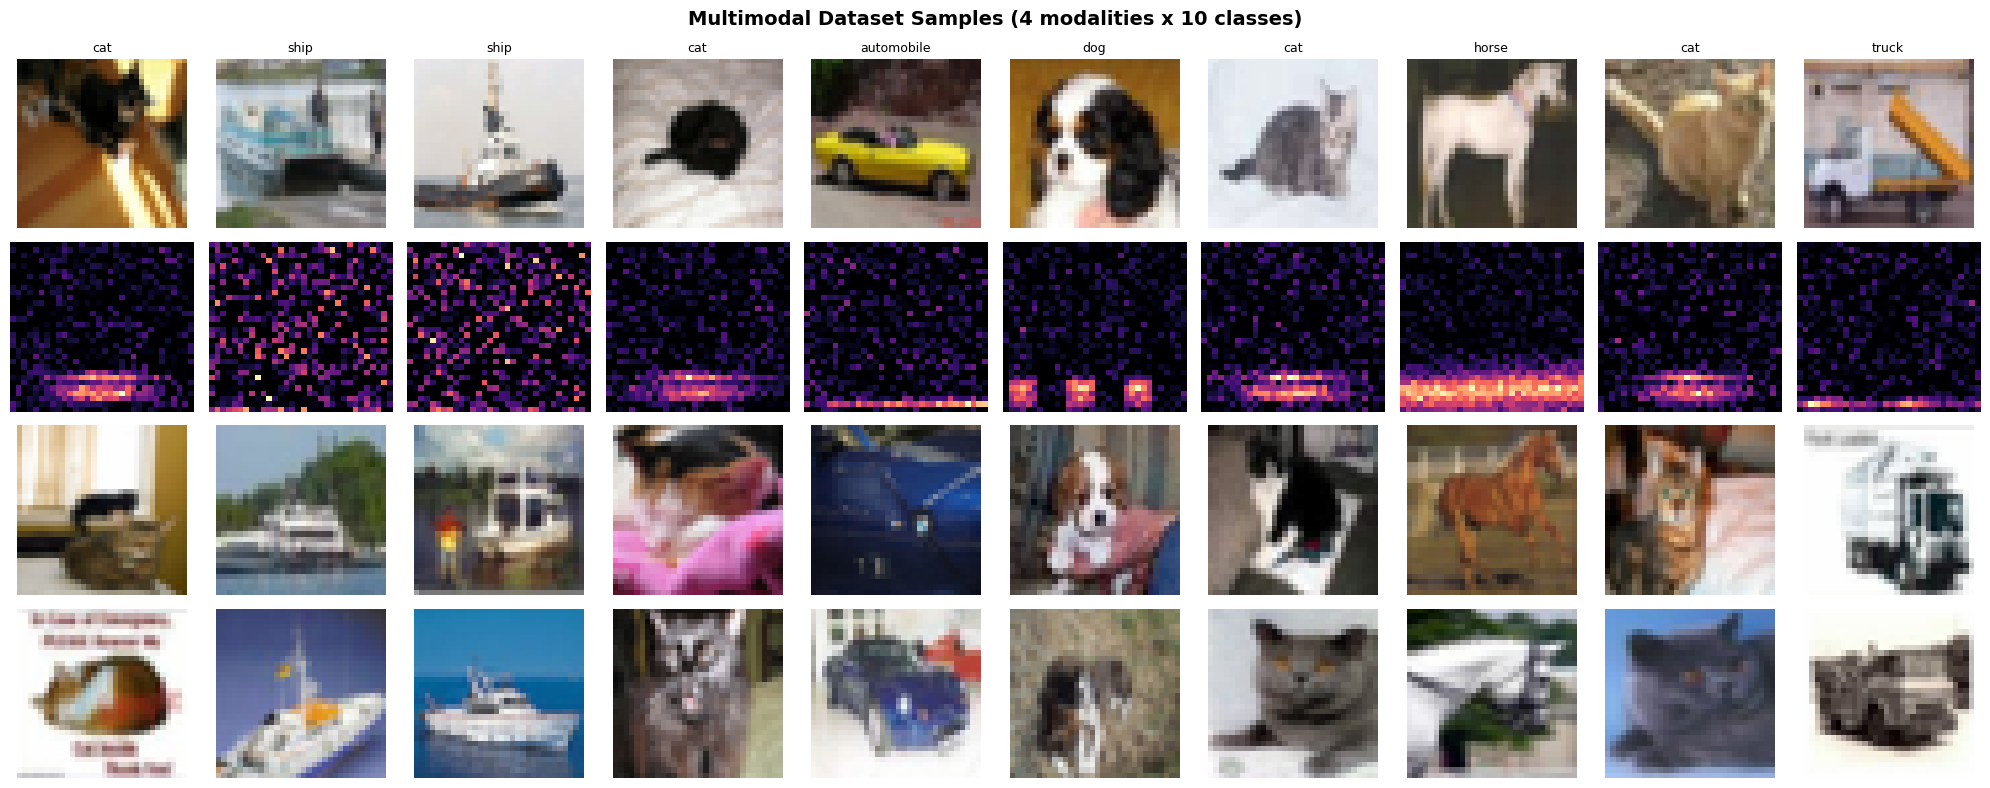

In [5]:
def make_synthetic_clip(image, video_len, rng=None):
    """
    image: CHW tensor (unnormalized, 0-1 range)
    Returns: (video_len, C, H, W) tensor - a smooth pan/zoom/rotate trajectory
    starting from `image`, giving genuine frame-to-frame continuity.
    """
    rng = rng or random
    angle_end  = rng.uniform(-12, 12)     # total rotation over the clip (deg)
    scale_end  = rng.uniform(0.9, 1.15)   # total zoom over the clip
    tx_end     = rng.uniform(-3, 3)       # total horizontal pan (px)
    ty_end     = rng.uniform(-3, 3)       # total vertical pan (px)

    frames = []
    for t in range(video_len):
        frac = t / max(video_len - 1, 1)
        angle = angle_end * frac
        scale = 1.0 + (scale_end - 1.0) * frac
        tx, ty = tx_end * frac, ty_end * frac
        frame = TF.affine(image, angle=angle, translate=[int(round(tx)), int(round(ty))],
                          scale=scale, shear=0)
        frames.append(frame)
    return torch.stack(frames, dim=0)


class MultiModalDataset(Dataset):
    """
    Unified dataset providing 4 modalities for each sample:
      1. Image  - CIFAR-10 image (3x32x32)
      2. Audio  - Synthetic mel-spectrogram, per-sample randomized (1x32x32)
      3. Text   - Tokenized description (max_len,)
      4. Video  - Synthetic camera-motion clip from the image (Tx3x32x32)
      5. Label  - Class index
    """
    def __init__(self, cifar_dataset):
        self.cifar = cifar_dataset
        self.texts = []
        for idx in range(len(self.cifar)):
            _, label = self.cifar[idx]
            tpl = random.choice(TEMPLATES)
            self.texts.append(text_to_indices(tpl.format(CLASS_NAMES[label])))

        self.normalize = transforms.Normalize(
            (0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))

    def __len__(self):
        return len(self.cifar)

    def __getitem__(self, idx):
        image, label = self.cifar[idx]          # raw [0,1] tensor, CHW

        spectrogram = AudioGenerator.generate(label, size=cfg.IMG_SIZE)
        spectrogram = torch.FloatTensor(spectrogram).unsqueeze(0)

        text = torch.LongTensor(self.texts[idx])

        # Real temporal structure: smooth pan/zoom/rotate trajectory from this image
        video_raw = make_synthetic_clip(image, cfg.VIDEO_LEN)
        video = torch.stack([self.normalize(f) for f in video_raw], dim=0)

        image_n = self.normalize(image)

        return {
            'image': image_n,
            'audio': spectrogram,
            'text': text,
            'video': video,
            'label': label,
        }


print("Downloading CIFAR-10...")
transform = transforms.Compose([transforms.ToTensor()])
cifar_train = torchvision.datasets.CIFAR10(root='./data', train=True,
                                           download=True, transform=transform)
cifar_test  = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform)

train_dataset = MultiModalDataset(cifar_train)
test_dataset  = MultiModalDataset(cifar_test)

train_loader = DataLoader(train_dataset, batch_size=cfg.BATCH_SIZE,
                          shuffle=True, num_workers=0, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=cfg.BATCH_SIZE,
                          shuffle=False, num_workers=0, pin_memory=True)

print(f"Dataset ready: {len(train_dataset)} train, {len(test_dataset)} test")

# Visualize samples
fig, axes = plt.subplots(4, 10, figsize=(20, 8))
sample_batch = next(iter(DataLoader(test_dataset, batch_size=10, shuffle=True)))
row_labels = ['Image', 'Audio', 'Video[0]', 'Video[3]']
mean_t = np.array([0.4914, 0.4822, 0.4465])
std_t  = np.array([0.2023, 0.1994, 0.2010])
for col in range(10):
    img = sample_batch['image'][col].permute(1, 2, 0).numpy() * std_t + mean_t
    axes[0, col].imshow(np.clip(img, 0, 1))
    axes[0, col].set_title(CLASS_NAMES[sample_batch['label'][col]], fontsize=9)
    axes[1, col].imshow(sample_batch['audio'][col, 0].numpy(), cmap='magma',
                         aspect='auto', origin='lower')
    vf0 = sample_batch['video'][col, 0].permute(1, 2, 0).numpy() * std_t + mean_t
    axes[2, col].imshow(np.clip(vf0, 0, 1))
    vf3 = sample_batch['video'][col, 3].permute(1, 2, 0).numpy() * std_t + mean_t
    axes[3, col].imshow(np.clip(vf3, 0, 1))

for r in range(4):
    for c in range(10):
        axes[r, c].axis('off')
    axes[r, 0].set_ylabel(row_labels[r], fontsize=11, rotation=0, labelpad=55, va='center')
plt.suptitle("Multimodal Dataset Samples (4 modalities x 10 classes)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("dataset_preview.png", dpi=100, bbox_inches='tight')
plt.show()


## SECTION 5: MODEL ARCHITECTURE


In [6]:
# --- 5a. Visual Tokenizer (shared for image, audio, video frames) ---

class VisualTokenizer(nn.Module):
    """Lightweight CNN converting 2D spatial data (image / audio spectrogram
    / video frame) to a feature vector. Each modality gets its own instance
    of this tokenizer; video reuses the image tokenizer's weights via
    VideoTokenizer."""
    def __init__(self, in_channels=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 64, 3, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.LeakyReLU(0.2),
            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.Conv2d(128, 256, 3, stride=2, padding=1),
            nn.BatchNorm2d(256), nn.LeakyReLU(0.2),
            nn.AdaptiveAvgPool2d(1),
        )
        self.project = nn.Linear(256, cfg.FEAT_DIM)

    def forward(self, x):
        h = self.features(x).squeeze(-1).squeeze(-1)
        return self.project(h)


In [7]:
# --- 5b. Text Tokenizer ---

class TextTokenizer(nn.Module):
    """Embedding + GRU converting token sequences to a feature vector."""
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(VOCAB_SIZE, cfg.TEXT_EMBED_DIM,
                                      padding_idx=cfg.PAD_IDX)
        self.gru = nn.GRU(cfg.TEXT_EMBED_DIM, cfg.HIDDEN_DIM,
                          batch_first=True, num_layers=1)
        self.project = nn.Linear(cfg.HIDDEN_DIM, cfg.FEAT_DIM)

    def forward(self, x):
        emb = self.embedding(x)
        _, h = self.gru(emb)
        return self.project(h.squeeze(0))


In [8]:
# --- 5c. Video Tokenizer ---

class VideoTokenizer(nn.Module):
    """Processes video frames with shared VisualTokenizer + temporal attention."""
    def __init__(self, visual_tokenizer):
        super().__init__()
        self.visual_tokenizer = visual_tokenizer
        self.temporal_attn = nn.Sequential(
            nn.Linear(cfg.FEAT_DIM, 64), nn.Tanh(), nn.Linear(64, 1))

    def forward(self, x):
        B, T, C, H, W = x.shape
        feats = self.visual_tokenizer(x.reshape(B * T, C, H, W))
        feats = feats.reshape(B, T, cfg.FEAT_DIM)
        attn = F.softmax(self.temporal_attn(feats), dim=1)
        return (feats * attn).sum(dim=1)


In [9]:
# --- 5d. Shared Encoder (VAE) ---

class SharedEncoder(nn.Module):
    """ONE shared encoder for ALL modalities. Maps features to latent space."""
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(cfg.FEAT_DIM, cfg.HIDDEN_DIM),
            nn.LayerNorm(cfg.HIDDEN_DIM), nn.LeakyReLU(0.2), nn.Dropout(0.1),
            nn.Linear(cfg.HIDDEN_DIM, cfg.HIDDEN_DIM),
            nn.LayerNorm(cfg.HIDDEN_DIM), nn.LeakyReLU(0.2),
        )
        self.fc_mu     = nn.Linear(cfg.HIDDEN_DIM, cfg.LATENT_DIM)
        self.fc_logvar = nn.Linear(cfg.HIDDEN_DIM, cfg.LATENT_DIM)

    def forward(self, features):
        h = self.encoder(features)
        return self.fc_mu(h), self.fc_logvar(h)

    @staticmethod
    def reparameterize(mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std


In [10]:
# --- 5e. Visual Decoder ---

class VisualDecoder(nn.Module):
    """Decodes latent z back to image for reconstruction loss."""
    def __init__(self, out_channels=3):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(cfg.LATENT_DIM, 256 * 4 * 4), nn.LeakyReLU(0.2))
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1),
            nn.BatchNorm2d(128), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.BatchNorm2d(64), nn.LeakyReLU(0.2),
            nn.ConvTranspose2d(64, out_channels, 4, stride=2, padding=1),
            nn.Tanh(),
        )

    def forward(self, z):
        h = self.fc(z).reshape(-1, 256, 4, 4)
        return self.deconv(h)


In [11]:
# --- 5f. Text Decoder ---

class TextDecoder(nn.Module):
    """Autoregressive GRU decoder generating text from latent z."""
    def __init__(self):
        super().__init__()
        self.z_to_hidden = nn.Linear(cfg.LATENT_DIM, cfg.HIDDEN_DIM)
        self.embedding = nn.Embedding(VOCAB_SIZE, cfg.TEXT_EMBED_DIM,
                                      padding_idx=cfg.PAD_IDX)
        self.gru = nn.GRU(cfg.TEXT_EMBED_DIM, cfg.HIDDEN_DIM,
                          batch_first=True, num_layers=1)
        self.fc_out = nn.Linear(cfg.HIDDEN_DIM, VOCAB_SIZE)

    def forward(self, z, target_text=None):
        h = self.z_to_hidden(z).unsqueeze(0)
        if target_text is not None:
            emb = self.embedding(target_text[:, :-1])
            output, _ = self.gru(emb, h)
            return self.fc_out(output)
        else:
            B = z.size(0)
            token = torch.full((B, 1), cfg.SOS_IDX, dtype=torch.long, device=z.device)
            outputs = []
            for _ in range(cfg.MAX_TEXT_LEN - 1):
                emb = self.embedding(token)
                output, h = self.gru(emb, h)
                logit = self.fc_out(output)
                next_token = logit.argmax(dim=-1)
                outputs.append(next_token)
                token = next_token
            return torch.cat(outputs, dim=1)


In [12]:
# --- 5g. Dynamics Model (World Model) ---

class DynamicsModel(nn.Module):
    """Predicts future latent states. The WORLD MODEL component."""
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(cfg.LATENT_DIM, cfg.HIDDEN_DIM,
                          batch_first=True, num_layers=1)
        self.fc_out = nn.Linear(cfg.HIDDEN_DIM, cfg.LATENT_DIM)

    def forward(self, z_sequence):
        output, _ = self.gru(z_sequence)
        return self.fc_out(output)

    def predict_future(self, z_current, steps=4):
        predictions = [z_current]
        h = None
        z = z_current.unsqueeze(1)
        for _ in range(steps):
            output, h = self.gru(z, h)
            z_next = self.fc_out(output)
            predictions.append(z_next.squeeze(1))
            z = z_next
        return torch.stack(predictions, dim=1)


In [13]:
# --- 5h. Full UMWM Assembly ---

class UMWM(nn.Module):
    """Unified Multimodal World Model — complete architecture."""
    def __init__(self):
        super().__init__()
        self.image_tokenizer = VisualTokenizer(in_channels=3)
        self.audio_tokenizer = VisualTokenizer(in_channels=1)
        self.text_tokenizer  = TextTokenizer()
        self.video_tokenizer = VideoTokenizer(self.image_tokenizer)

        self.shared_encoder = SharedEncoder()
        self.visual_decoder = VisualDecoder(out_channels=3)
        self.text_decoder   = TextDecoder()
        self.dynamics_model = DynamicsModel()
        self.classifier     = nn.Linear(cfg.LATENT_DIM, cfg.NUM_CLASSES)

    def tokenize(self, batch, modality):
        if modality == 'image':  return self.image_tokenizer(batch)
        elif modality == 'audio':  return self.audio_tokenizer(batch)
        elif modality == 'text':   return self.text_tokenizer(batch)
        elif modality == 'video':  return self.video_tokenizer(batch)

    def encode(self, batch, modality):
        features = self.tokenize(batch, modality)
        mu, logvar = self.shared_encoder(features)
        z = SharedEncoder.reparameterize(mu, logvar)
        return mu, logvar, z

    def forward(self, batch, modality):
        mu, logvar, z = self.encode(batch, modality)
        recon = self.visual_decoder(z) if modality in ('image', 'video') else None
        return mu, logvar, z, recon

    def count_parameters(self):
        components = {
            'Image Tokenizer': self.image_tokenizer,
            'Audio Tokenizer': self.audio_tokenizer,
            'Text Tokenizer': self.text_tokenizer,
            'Video Temporal Attn': self.video_tokenizer.temporal_attn,
            'Shared Encoder': self.shared_encoder,
            'Visual Decoder': self.visual_decoder,
            'Text Decoder': self.text_decoder,
            'Dynamics Model': self.dynamics_model,
            'Classifier': self.classifier,
        }
        total = 0
        print("\nParameter Count:")
        print("-" * 50)
        for name, module in components.items():
            n = sum(p.numel() for p in module.parameters())
            total += n
            print(f"  {name:35s} {n:>10,}")
        print("-" * 50)
        print(f"  {'TOTAL':35s} {total:>10,}")
        return total

model = UMWM().to(DEVICE)
model.count_parameters()
print(f"\nModel built on {DEVICE}")



Parameter Count:
--------------------------------------------------
  Image Tokenizer                        503,296
  Audio Tokenizer                        502,144
  Text Tokenizer                         381,120
  Video Temporal Attn                     32,897
  Shared Encoder                         263,936
  Visual Decoder                       1,187,395
  Text Decoder                           291,555
  Dynamics Model                         329,344
  Classifier                               1,290
--------------------------------------------------
  TOTAL                                3,492,977

Model built on cuda


## SECTION 6: LOSS FUNCTIONS


In [14]:
def vae_loss(recon, target, mu, logvar, beta=cfg.BETA_KL):
    recon_loss = F.mse_loss(recon, target, reduction='mean')
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + beta * kl_loss, recon_loss, kl_loss

def nt_xent_loss(z_a, z_b, temperature=cfg.TEMPERATURE):
    z_a = F.normalize(z_a, dim=1)
    z_b = F.normalize(z_b, dim=1)
    B = z_a.size(0)
    sim = torch.mm(z_a, z_b.t()) / temperature
    labels = torch.arange(B, device=z_a.device)
    return F.cross_entropy(sim, labels)


## SECTION 7: PHASE 1 — VAE RECONSTRUCTION



  PHASE 1: VAE Training (Reconstruction + KL)


P1 [1/30]:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch   1 | Total: 2.6525 | Recon: 1.0540 | KL: 0.0993


P1 [2/30]:   0%|          | 0/391 [00:00<?, ?it/s]

P1 [3/30]:   0%|          | 0/391 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
self._shutdown_workers()    
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():    
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
if w.is_alive():    assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError:   File "/usr/lib/python3.13/multiprocessing/pro

P1 [29/30]:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
Exception ignored

P1 [30/30]:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch  30 | Total: 2.2578 | Recon: 0.7326 | KL: 0.1108
Phase 1 complete


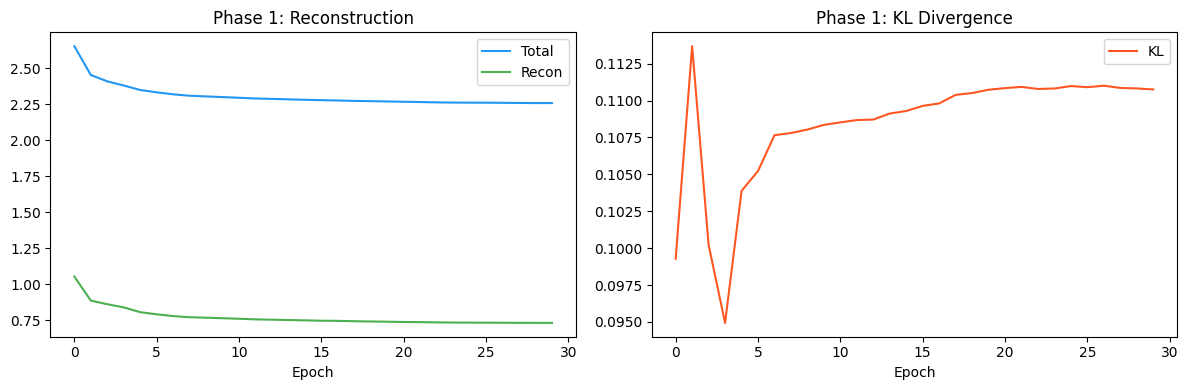

In [15]:
print("\n" + "=" * 70)
print("  PHASE 1: VAE Training (Reconstruction + KL)")
print("=" * 70)

optimizer = optim.Adam(model.parameters(), lr=cfg.LR, weight_decay=1e-5)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.EPOCHS_PHASE1)
history_p1 = {'total': [], 'recon': [], 'kl': []}

for epoch in range(cfg.EPOCHS_PHASE1):
    model.train()
    ep = {'total': 0, 'recon': 0, 'kl': 0}
    n = 0
    for batch in tqdm(train_loader, desc=f"P1 [{epoch+1}/{cfg.EPOCHS_PHASE1}]", leave=False):
        images = batch['image'].to(DEVICE)
        audio  = batch['audio'].to(DEVICE)
        text   = batch['text'].to(DEVICE)
        video  = batch['video'].to(DEVICE)

        optimizer.zero_grad()
        total = 0

        # Image reconstruction
        mu_i, lv_i, z_i, recon_i = model(images, 'image')
        loss_i, rl_i, kl_i = vae_loss(recon_i, images, mu_i, lv_i)
        total += loss_i

        # Audio -> encode -> decode to image space
        mu_a, lv_a, z_a = model.encode(audio, 'audio')
        recon_a = model.visual_decoder(z_a)
        loss_a, _, _ = vae_loss(recon_a, images, mu_a, lv_a)
        total += 0.5 * loss_a

        # Text -> encode (KL only, no visual reconstruction)
        mu_t, lv_t, z_t = model.encode(text, 'text')
        kl_t = -0.5 * torch.mean(1 + lv_t - mu_t.pow(2) - lv_t.exp())
        total += cfg.BETA_KL * kl_t

        # Video -> encode -> decode
        mu_v, lv_v, z_v, recon_v = model(video, 'video')
        loss_v, _, _ = vae_loss(recon_v, images, mu_v, lv_v)
        total += 0.5 * loss_v

        total.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        ep['total'] += total.item()
        ep['recon'] += rl_i.item()
        ep['kl'] += kl_i.item()
        n += 1

    scheduler.step()
    for k in ep: ep[k] /= n; history_p1[k].append(ep[k])
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"  Epoch {epoch+1:3d} | Total: {ep['total']:.4f} | "
              f"Recon: {ep['recon']:.4f} | KL: {ep['kl']:.4f}")

print("Phase 1 complete")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history_p1['total'], label='Total', color='#2196F3')
ax1.plot(history_p1['recon'], label='Recon', color='#4CAF50')
ax1.set_title('Phase 1: Reconstruction'); ax1.legend(); ax1.set_xlabel('Epoch')
ax2.plot(history_p1['kl'], label='KL', color='#FF5722')
ax2.set_title('Phase 1: KL Divergence'); ax2.legend(); ax2.set_xlabel('Epoch')
plt.tight_layout(); plt.savefig("phase1_loss.png", dpi=100); plt.show()


## SECTION 8: PHASE 2 — CONTRASTIVE ALIGNMENT



  PHASE 2: Contrastive Alignment (Cross-Modal)


P2 [1/20]:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch   1 | Contrastive: 4.2527 | Total: 4.5792


P2 [2/20]:   0%|          | 0/391 [00:00<?, ?it/s]

P2 [3/20]:   0%|          | 0/391 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

P2 [19/20]:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

P2 [20/20]:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch  20 | Contrastive: 2.9899 | Total: 3.3047
Phase 2 complete


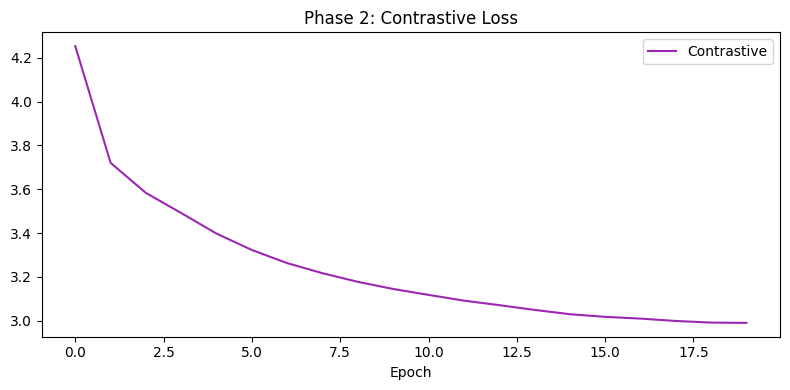

In [16]:
print("\n" + "=" * 70)
print("  PHASE 2: Contrastive Alignment (Cross-Modal)")
print("=" * 70)

opt2 = optim.Adam(model.parameters(), lr=cfg.LR * 0.5, weight_decay=1e-5)
sch2 = optim.lr_scheduler.CosineAnnealingLR(opt2, T_max=cfg.EPOCHS_PHASE2)
history_p2 = {'contrastive': [], 'total': []}

for epoch in range(cfg.EPOCHS_PHASE2):
    model.train()
    ep = {'contrastive': 0, 'total': 0}
    n = 0
    for batch in tqdm(train_loader, desc=f"P2 [{epoch+1}/{cfg.EPOCHS_PHASE2}]", leave=False):
        images = batch['image'].to(DEVICE)
        audio  = batch['audio'].to(DEVICE)
        text   = batch['text'].to(DEVICE)
        video  = batch['video'].to(DEVICE)

        opt2.zero_grad()
        _, _, z_img = model.encode(images, 'image')
        _, _, z_aud = model.encode(audio,  'audio')
        _, _, z_txt = model.encode(text,   'text')
        _, _, z_vid = model.encode(video,  'video')

        # 6 contrastive pairs (all combinations)
        cl = (nt_xent_loss(z_img, z_aud) + nt_xent_loss(z_img, z_txt) +
              nt_xent_loss(z_img, z_vid) + nt_xent_loss(z_aud, z_txt) +
              nt_xent_loss(z_aud, z_vid) + nt_xent_loss(z_txt, z_vid)) / 6

        # Keep VAE alive
        mu_i, lv_i, _, recon_i = model(images, 'image')
        vl, _, _ = vae_loss(recon_i, images, mu_i, lv_i)
        total = cfg.LAMBDA_CONTRAST * cl + 0.3 * vl

        total.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt2.step()
        ep['contrastive'] += cl.item()
        ep['total'] += total.item()
        n += 1

    sch2.step()
    for k in ep: ep[k] /= n; history_p2[k].append(ep[k])
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"  Epoch {epoch+1:3d} | Contrastive: {ep['contrastive']:.4f} | "
              f"Total: {ep['total']:.4f}")

print("Phase 2 complete")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_p2['contrastive'], label='Contrastive', color='#9C27B0')
ax.set_title('Phase 2: Contrastive Loss'); ax.legend(); ax.set_xlabel('Epoch')
plt.tight_layout(); plt.savefig("phase2_loss.png", dpi=100); plt.show()


## SECTION 9: PHASE 3 — TEXT DECODER



  PHASE 3: Text Decoder (generate text from any modality)


P3 [1/20]:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch   1 | Text CE: 0.9307


P3 [2/20]:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

...

P3 [19/20]:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

P3 [20/20]:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: Exception ignored in: can only test a child process
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Exception ignored in: Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__

    Traceback (most recent call last):
<function _MultiProcessingDat

  Epoch  20 | Text CE: 0.4355
Phase 3 complete


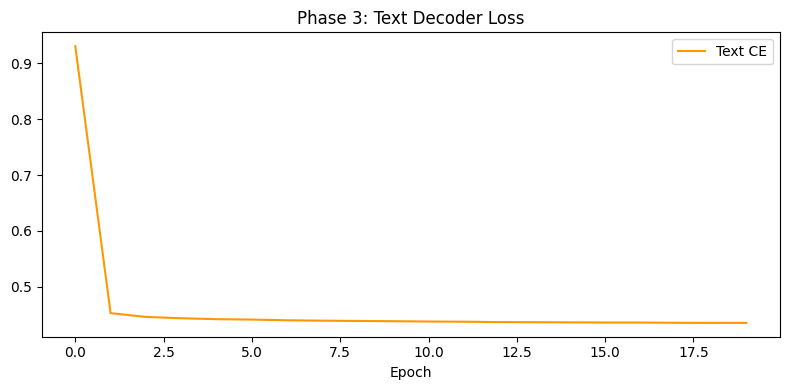

In [17]:
print("\n" + "=" * 70)
print("  PHASE 3: Text Decoder (generate text from any modality)")
print("=" * 70)

# Freeze encoder, train only text decoder
for p in model.image_tokenizer.parameters(): p.requires_grad = False
for p in model.audio_tokenizer.parameters(): p.requires_grad = False
for p in model.text_tokenizer.parameters():  p.requires_grad = False
for p in model.shared_encoder.parameters():  p.requires_grad = False

opt3 = optim.Adam(model.text_decoder.parameters(), lr=cfg.LR)
sch3 = optim.lr_scheduler.CosineAnnealingLR(opt3, T_max=cfg.EPOCHS_PHASE3)
history_p3 = {'text_loss': []}

for epoch in range(cfg.EPOCHS_PHASE3):
    model.train()
    el = 0; n = 0
    for batch in tqdm(train_loader, desc=f"P3 [{epoch+1}/{cfg.EPOCHS_PHASE3}]", leave=False):
        images = batch['image'].to(DEVICE)
        audio  = batch['audio'].to(DEVICE)
        text   = batch['text'].to(DEVICE)
        video  = batch['video'].to(DEVICE)

        opt3.zero_grad()
        total = 0
        for mod, data in [('image', images), ('audio', audio),
                          ('text', text), ('video', video)]:
            with torch.no_grad():
                _, _, z = model.encode(data, mod)
            logits = model.text_decoder(z, target_text=text)
            target = text[:, 1:]
            loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE),
                                   target.reshape(-1), ignore_index=cfg.PAD_IDX)
            total += loss
        total = total / 4
        total.backward()
        opt3.step()
        el += total.item(); n += 1

    sch3.step()
    avg = el / n; history_p3['text_loss'].append(avg)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"  Epoch {epoch+1:3d} | Text CE: {avg:.4f}")

for p in model.parameters(): p.requires_grad = True
print("Phase 3 complete")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_p3['text_loss'], label='Text CE', color='#FF9800')
ax.set_title('Phase 3: Text Decoder Loss'); ax.legend(); ax.set_xlabel('Epoch')
plt.tight_layout(); plt.savefig("phase3_loss.png", dpi=100); plt.show()


## SECTION 10: PHASE 4 — DYNAMICS (WORLD MODEL)



  PHASE 4: Dynamics Model (World Model — predict future states)


P4 [1/15]:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch   1 | Dynamics MSE: 0.681233


P4 [2/15]:   0%|          | 0/391 [00:00<?, ?it/s]

P4 [3/15]:   0%|          | 0/391 [00:00<?, ?it/s]

...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
self._shutdown_workers()  File "/usr/local/lib/pyth

P4 [14/15]:   0%|          | 0/391 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Exception ignored in:     <function _MultiProcessingDataLoaderIter.__del__ at 0x7f3a34532160>assert self._parent_pid == os.getpid(), 'can only test a child process'

Traceback (most recent call last):
AssertionError  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
:     can only test a child process
self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    Exception ignored in: if w.is_aliv

P4 [15/15]:   0%|          | 0/391 [00:00<?, ?it/s]

  Epoch  15 | Dynamics MSE: 0.626510
Phase 4 complete


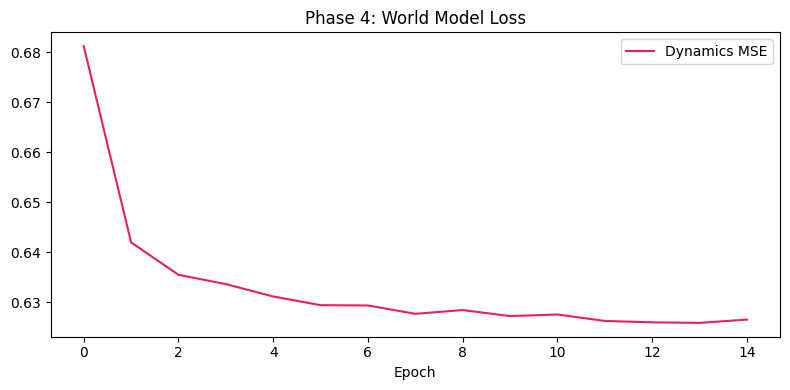


Training classifier head...
Classifier trained


In [18]:
print("\n" + "=" * 70)
print("  PHASE 4: Dynamics Model (World Model — predict future states)")
print("=" * 70)

for p in model.parameters(): p.requires_grad = False
for p in model.dynamics_model.parameters(): p.requires_grad = True

opt4 = optim.Adam(model.dynamics_model.parameters(), lr=cfg.LR)
history_p4 = {'dynamics': []}

for epoch in range(cfg.EPOCHS_PHASE4):
    model.train()
    el = 0; n = 0
    for batch in tqdm(train_loader, desc=f"P4 [{epoch+1}/{cfg.EPOCHS_PHASE4}]", leave=False):
        video = batch['video'].to(DEVICE)
        B, T, C, H, W = video.shape

        opt4.zero_grad()
        with torch.no_grad():
            z_frames = []
            for t in range(T):
                _, _, z_t = model.encode(video[:, t], 'image')
                z_frames.append(z_t)
            z_seq = torch.stack(z_frames, dim=1)

        z_pred = model.dynamics_model(z_seq[:, :-1])
        loss = F.mse_loss(z_pred, z_seq[:, 1:])
        loss.backward()
        opt4.step()
        el += loss.item(); n += 1

    avg = el / n; history_p4['dynamics'].append(avg)
    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(f"  Epoch {epoch+1:3d} | Dynamics MSE: {avg:.6f}")

for p in model.parameters(): p.requires_grad = True
print("Phase 4 complete")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history_p4['dynamics'], label='Dynamics MSE', color='#E91E63')
ax.set_title('Phase 4: World Model Loss'); ax.legend(); ax.set_xlabel('Epoch')
plt.tight_layout(); plt.savefig("phase4_loss.png", dpi=100); plt.show()

# Train classifier head
print("\nTraining classifier head...")
for p in model.parameters(): p.requires_grad = False
for p in model.classifier.parameters(): p.requires_grad = True
opt_c = optim.Adam(model.classifier.parameters(), lr=1e-3)
for ep in range(10):
    model.train()
    for batch in train_loader:
        imgs = batch['image'].to(DEVICE); labs = batch['label'].to(DEVICE)
        opt_c.zero_grad()
        with torch.no_grad(): _, _, z = model.encode(imgs, 'image')
        loss = F.cross_entropy(model.classifier(z), labs)
        loss.backward(); opt_c.step()
for p in model.parameters(): p.requires_grad = True
print("Classifier trained")


## SECTION 11: EVALUATION & VISUALIZATION


In [19]:
print("\n" + "=" * 70)
print("  EVALUATION & VISUALIZATION")
print("=" * 70)
model.eval()



  EVALUATION & VISUALIZATION


UMWM(
  (image_tokenizer): VisualTokenizer(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): LeakyReLU(negative_slope=0.2)
      (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): LeakyReLU(negative_slope=0.2)
      (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (7): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (8): LeakyReLU(negative_slope=0.2)
      (9): AdaptiveAvgPool2d(output_size=1)
    )
    (project): Linear(in_features=256, out_features=512, bias=True)
  )
  (audio_tokenizer): VisualTokenizer(
    (features): Sequential(
      (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e

In [20]:
# --- 11a. Collect embeddings ---
all_z = {'image': [], 'audio': [], 'text': [], 'video': []}
all_labels = []
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Encoding test set"):
        for mod in ['image', 'audio', 'text', 'video']:
            _, _, z = model.encode(batch[mod].to(DEVICE), mod)
            all_z[mod].append(z.cpu())
        all_labels.append(batch['label'])

for k in all_z: all_z[k] = torch.cat(all_z[k])
all_labels = torch.cat(all_labels)
print(f"Encoded {len(all_labels)} test samples x 4 modalities")


Encoding test set:   0%|          | 0/79 [00:00<?, ?it/s]

Encoded 10000 test samples x 4 modalities



Computing t-SNE...


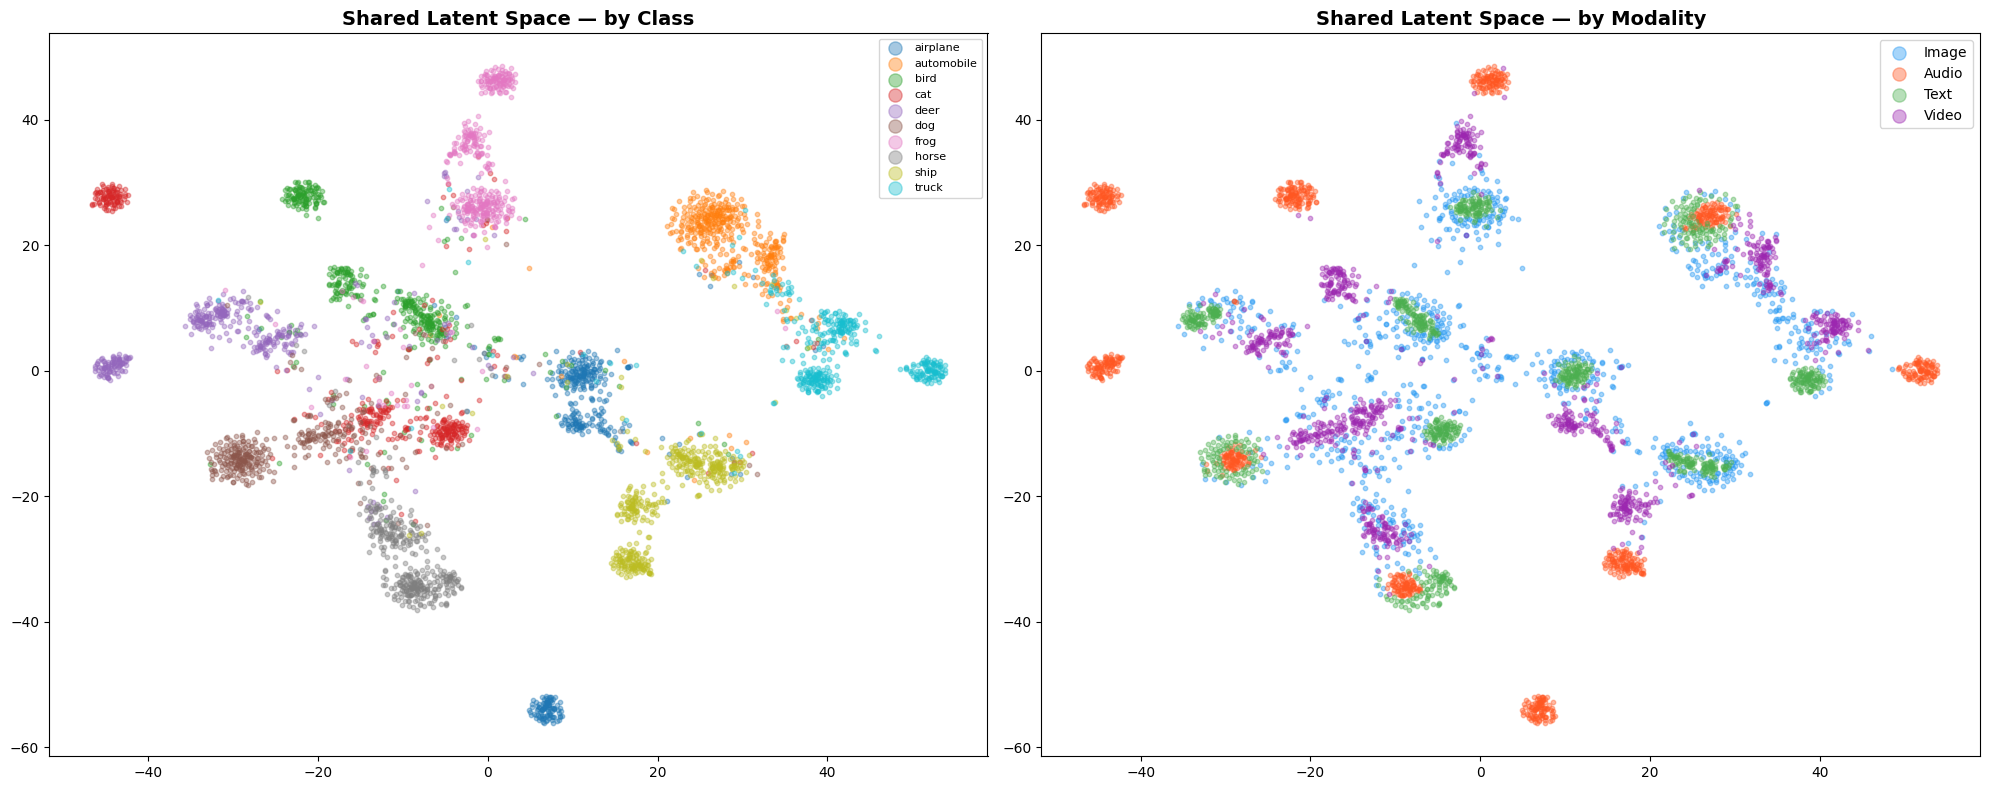

In [21]:
# --- 11b. t-SNE ---
print("\nComputing t-SNE...")
N_VIS = 1000
idx = np.random.choice(len(all_labels), N_VIS, replace=False)
z_comb = torch.cat([all_z[m][idx] for m in ['image','audio','text','video']]).numpy()
lab_comb = np.tile(all_labels[idx].numpy(), 4)
mod_lab = np.repeat(['Image', 'Audio', 'Text', 'Video'], N_VIS)

tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, n_iter=1000)
z_2d = tsne.fit_transform(z_comb)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for i in range(10):
    mask = lab_comb == i
    ax1.scatter(z_2d[mask, 0], z_2d[mask, 1], c=[colors[i]],
                label=CLASS_NAMES[i], alpha=0.4, s=10)
ax1.legend(fontsize=8, markerscale=3)
ax1.set_title("Shared Latent Space — by Class", fontsize=14, fontweight='bold')

mc = {'Image': '#2196F3', 'Audio': '#FF5722', 'Text': '#4CAF50', 'Video': '#9C27B0'}
for mod in mc:
    mask = mod_lab == mod
    ax2.scatter(z_2d[mask, 0], z_2d[mask, 1], c=mc[mod], label=mod, alpha=0.4, s=10)
ax2.legend(fontsize=10, markerscale=3)
ax2.set_title("Shared Latent Space — by Modality", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("tsne_latent_space.png", dpi=150, bbox_inches='tight')
plt.show()


In [22]:
# --- 11c. Cross-Modal Retrieval ---
print("\nCross-Modal Retrieval Accuracy:")
print("-" * 55)
print(f"  {'Query -> Gallery':25s} {'Top-1':>8s} {'Top-5':>8s}")
print("-" * 55)

N_R = 2000
ri = np.random.choice(len(all_labels), N_R, replace=False)
lab_r = all_labels[ri]

def ret_acc(zq, zg, labs, k=5):
    zq = F.normalize(zq, dim=1); zg = F.normalize(zg, dim=1)
    sim = torch.mm(zq, zg.t())
    t1 = 0; tk = 0
    for i in range(len(labs)):
        _, top = sim[i].topk(k)
        if labs[top[0]] == labs[i]: t1 += 1
        if labs[i] in labs[top]: tk += 1
    return t1/len(labs)*100, tk/len(labs)*100

for m1 in ['image','audio','text','video']:
    for m2 in ['image','audio','text','video']:
        if m1 != m2:
            t1, t5 = ret_acc(all_z[m1][ri], all_z[m2][ri], lab_r)
            print(f"  {m1:8s} -> {m2:8s}      {t1:6.1f}%  {t5:6.1f}%")
print("-" * 55)



Cross-Modal Retrieval Accuracy:
-------------------------------------------------------
  Query -> Gallery             Top-1    Top-5
-------------------------------------------------------
  image    -> audio           66.1%    67.3%
  image    -> text            65.9%    67.2%
  image    -> video           64.6%    77.5%
  audio    -> image           80.0%   100.0%
  audio    -> text           100.0%   100.0%
  audio    -> video          100.0%   100.0%
  text     -> image           77.0%   100.0%
  text     -> audio          100.0%   100.0%
  text     -> video          100.0%   100.0%
  video    -> image           70.7%    98.4%
  video    -> audio           93.9%    94.2%
  video    -> text            94.1%    94.2%
-------------------------------------------------------


In [23]:
# --- 11d. Text Generation ---
print("\nText Generation from Each Modality:")
print("-" * 70)
with torch.no_grad():
    tb = next(iter(DataLoader(test_dataset, batch_size=5, shuffle=True)))
    for mod, data in [('image', tb['image']), ('audio', tb['audio']),
                      ('text', tb['text']), ('video', tb['video'])]:
        _, _, z = model.encode(data.to(DEVICE), mod)
        gen = model.text_decoder(z)
        print(f"\n  [{mod.upper()}]:")
        for i in range(5):
            label = CLASS_NAMES[tb['label'][i]]
            gt = indices_to_text(gen[i].cpu().tolist())
            print(f"    True: {label:12s} | Generated: {gt}")



Text Generation from Each Modality:
----------------------------------------------------------------------

  [IMAGE]:
    True: horse        | Generated: a horse captured on camera
    True: deer         | Generated: a deer captured on camera
    True: dog          | Generated: a dog captured on camera
    True: truck        | Generated: a truck in the wild
    True: deer         | Generated: a deer captured on camera

  [AUDIO]:
    True: horse        | Generated: a horse captured on camera
    True: deer         | Generated: a deer captured on camera
    True: dog          | Generated: a dog in the wild
    True: truck        | Generated: a truck in the wild
    True: deer         | Generated: a deer in the wild

  [TEXT]:
    True: horse        | Generated: a photo of a horse
    True: deer         | Generated: a deer in the wild
    True: dog          | Generated: a dog in the wild
    True: truck        | Generated: a truck captured on camera
    True: deer         | Generated: 


Reconstruction Visualization...


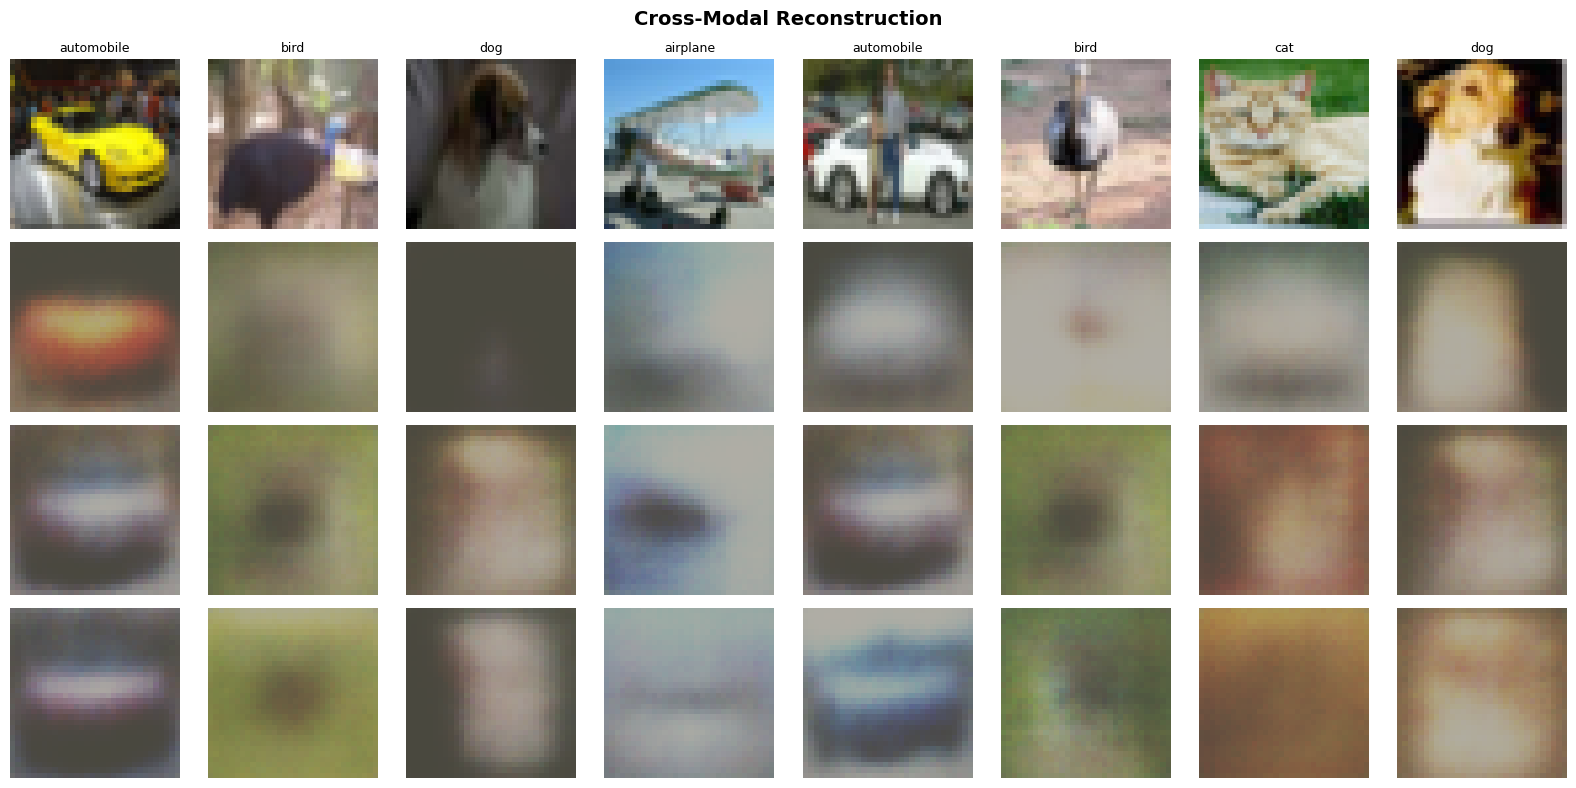

In [24]:
# --- 11e. Reconstruction ---
print("\nReconstruction Visualization...")
def denorm(t):
    m = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
    s = torch.tensor([0.2023, 0.1994, 0.2010]).view(3, 1, 1)
    return torch.clamp(t.cpu() * s + m, 0, 1)

with torch.no_grad():
    tb = next(iter(DataLoader(test_dataset, batch_size=8, shuffle=True)))
    imgs = tb['image'].to(DEVICE)
    aud  = tb['audio'].to(DEVICE)
    vid  = tb['video'].to(DEVICE)

    _, _, _, ri = model(imgs, 'image')
    _, _, za = model.encode(aud, 'audio')
    ra = model.visual_decoder(za)
    _, _, _, rv = model(vid, 'video')

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
rl = ['Original', 'From Image', 'From Audio', 'From Video']
for i in range(8):
    axes[0, i].imshow(denorm(imgs[i]).permute(1, 2, 0))
    axes[1, i].imshow(denorm(ri[i]).permute(1, 2, 0))
    axes[2, i].imshow(denorm(ra[i]).permute(1, 2, 0))
    axes[3, i].imshow(denorm(rv[i]).permute(1, 2, 0))
    axes[0, i].set_title(CLASS_NAMES[tb['label'][i]], fontsize=9)
for r in range(4):
    for c in range(8): axes[r, c].axis('off')
    axes[r, 0].set_ylabel(rl[r], fontsize=10, rotation=0, labelpad=60, va='center')
plt.suptitle("Cross-Modal Reconstruction", fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("reconstruction.png", dpi=150); plt.show()



World Model Dreaming...


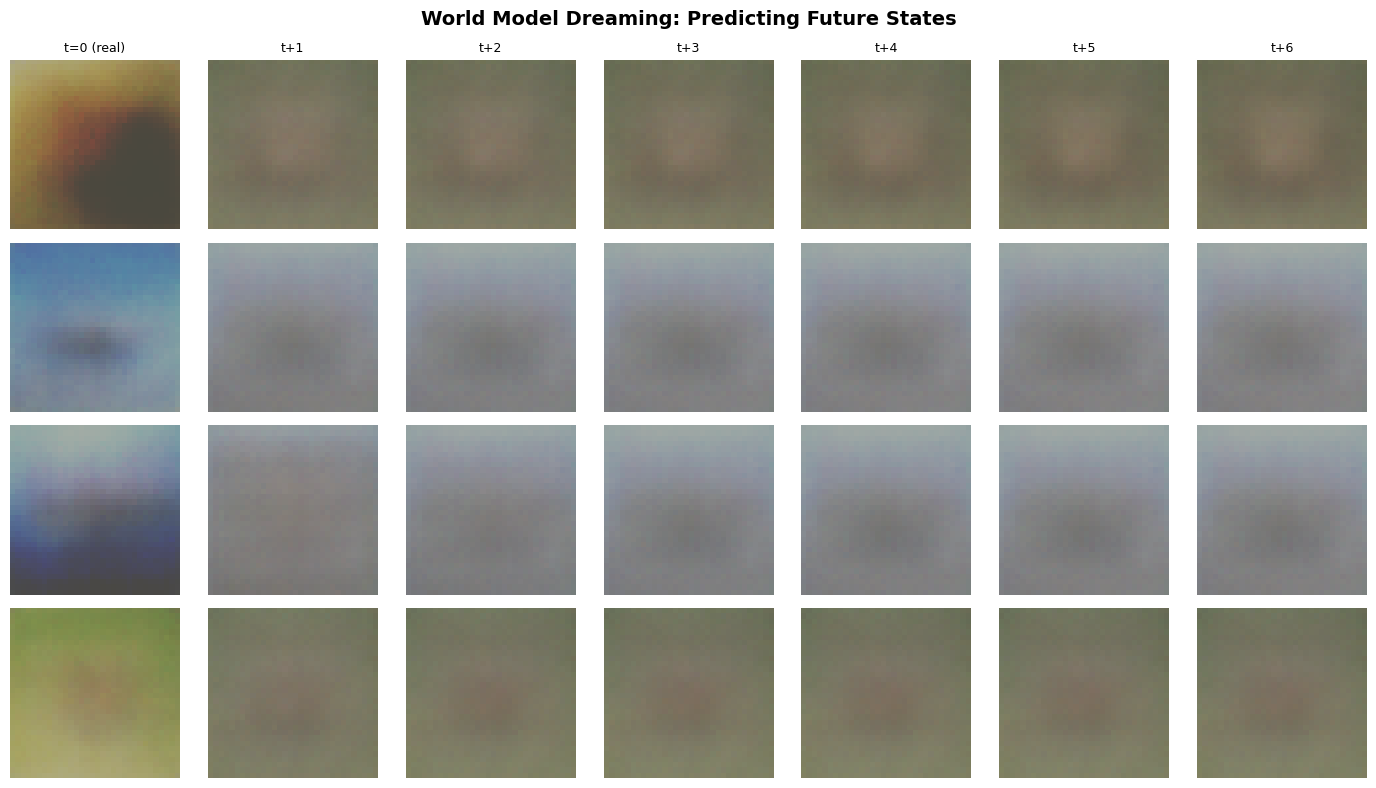

In [26]:
# --- 11f. World Model Dreaming ---
print("\nWorld Model Dreaming...")
with torch.no_grad():
    tb = next(iter(DataLoader(test_dataset, batch_size=4, shuffle=True)))
    _, _, zs = model.encode(tb['image'].to(DEVICE), 'image')
    # predict_future returns a sequence of latent states
    zf = model.dynamics_model.predict_future(zs, steps=6)

fig, axes = plt.subplots(4, 7, figsize=(14, 8))
for row in range(4):
    for t in range(7):
        # We use .detach() to ensure the tensor is removed from the gradient graph for plotting
        rec = model.visual_decoder(zf[row, t].unsqueeze(0)).detach()
        axes[row, t].imshow(denorm(rec[0]).permute(1, 2, 0))
        axes[row, t].axis('off')
        if row == 0:
            axes[row, t].set_title(f"{'t=0 (real)' if t==0 else f't+{t}'}", fontsize=9)
    axes[row, 0].set_ylabel(CLASS_NAMES[tb['label'][row]], fontsize=10,
                             rotation=0, labelpad=55, va='center')
plt.suptitle("World Model Dreaming: Predicting Future States",
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.savefig("world_model_dreaming.png", dpi=150); plt.show()

In [27]:
# --- 11g. Classification Accuracy ---
print("\nClassification Accuracy per Modality:")
print("-" * 40)
model.eval()
with torch.no_grad():
    for mod in ['image', 'audio', 'text', 'video']:
        cor = 0; tot = 0
        for batch in test_loader:
            d = batch[mod].to(DEVICE); l = batch['label'].to(DEVICE)
            _, _, z = model.encode(d, mod)
            cor += (model.classifier(z).argmax(1) == l).sum().item()
            tot += l.size(0)
        print(f"  {mod:8s}: {cor/tot*100:.1f}%")



Classification Accuracy per Modality:
----------------------------------------
  image   : 66.3%
  audio   : 100.0%
  text    : 100.0%
  video   : 93.9%



Cross-Modal Cosine Similarity:


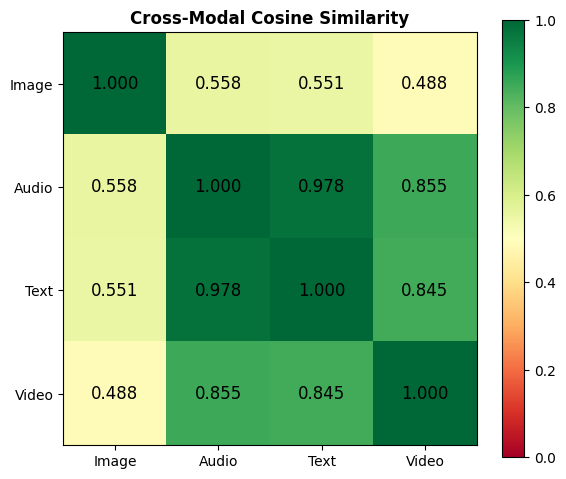

In [28]:
# --- 11h. Cosine Similarity Matrix ---
print("\nCross-Modal Cosine Similarity:")
mods = ['image', 'audio', 'text', 'video']
N_A = 1000; ai = np.random.choice(len(all_labels), N_A, replace=False)
sim_mat = np.zeros((4, 4))
for i, m1 in enumerate(mods):
    for j, m2 in enumerate(mods):
        z1 = F.normalize(all_z[m1][ai], dim=1)
        z2 = F.normalize(all_z[m2][ai], dim=1)
        sim_mat[i, j] = (z1 * z2).sum(dim=1).mean().item()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim_mat, cmap='RdYlGn', vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_yticks(range(4))
ax.set_xticklabels(['Image', 'Audio', 'Text', 'Video'])
ax.set_yticklabels(['Image', 'Audio', 'Text', 'Video'])
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{sim_mat[i,j]:.3f}", ha='center', va='center', fontsize=12)
plt.colorbar(im)
ax.set_title("Cross-Modal Cosine Similarity", fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig("cosine_similarity.png", dpi=150); plt.show()


## SECTION 12: ALL TRAINING CURVES


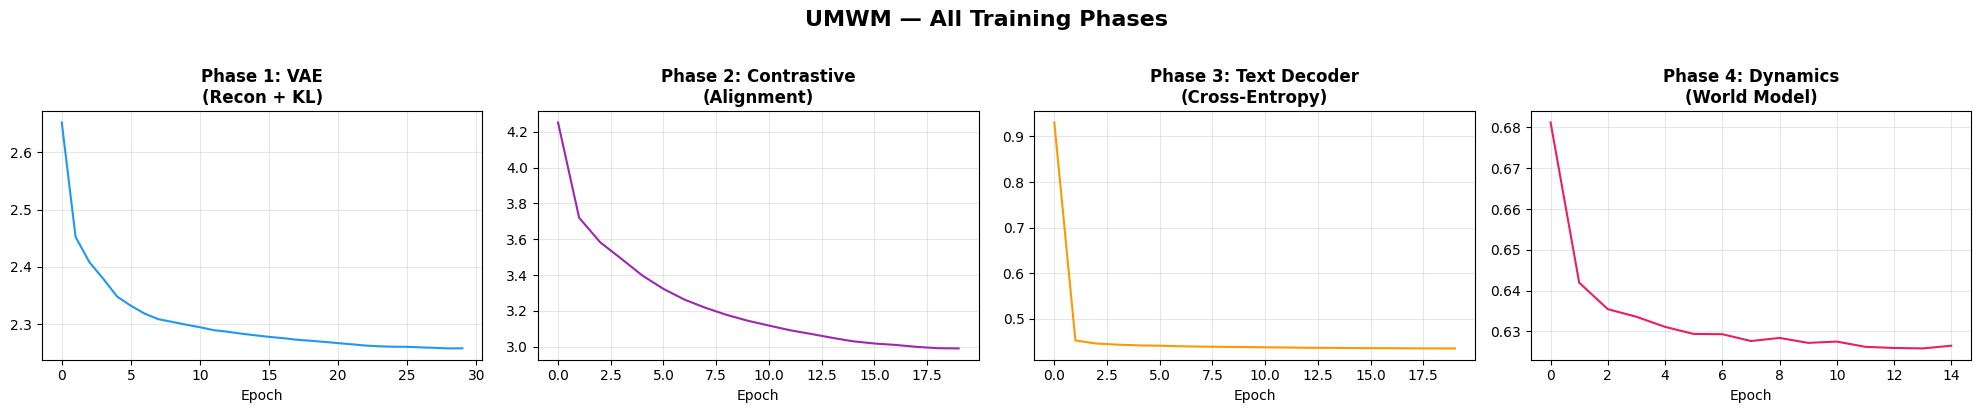

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(history_p1['total'], color='#2196F3')
axes[0].set_title('Phase 1: VAE\n(Recon + KL)', fontweight='bold')
axes[1].plot(history_p2['contrastive'], color='#9C27B0')
axes[1].set_title('Phase 2: Contrastive\n(Alignment)', fontweight='bold')
axes[2].plot(history_p3['text_loss'], color='#FF9800')
axes[2].set_title('Phase 3: Text Decoder\n(Cross-Entropy)', fontweight='bold')
axes[3].plot(history_p4['dynamics'], color='#E91E63')
axes[3].set_title('Phase 4: Dynamics\n(World Model)', fontweight='bold')
for ax in axes: ax.grid(True, alpha=0.3); ax.set_xlabel('Epoch')
plt.suptitle("UMWM — All Training Phases", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig("all_phases_loss.png", dpi=150); plt.show()


## SECTION 13: SAVE & SUMMARY


In [30]:
torch.save({'model': model.state_dict(), 'config': cfg.__dict__,
            'vocab': WORD2IDX, 'classes': CLASS_NAMES}, 'umwm_checkpoint.pth')
print("\nModel saved to umwm_checkpoint.pth")

print("\n" + "=" * 70)
print("  RESULTS SUMMARY")
print("=" * 70)
print(f"""
  Architecture:
    4 modalities: Image, Audio, Text, Video
    Shared latent dim: {cfg.LATENT_DIM}
    Total params: {sum(p.numel() for p in model.parameters()):,}

  Training (4 phases):
    P1 VAE:         {cfg.EPOCHS_PHASE1} epochs | Final recon: {history_p1['recon'][-1]:.4f}
    P2 Contrastive: {cfg.EPOCHS_PHASE2} epochs | Final: {history_p2['contrastive'][-1]:.4f}
    P3 Text:        {cfg.EPOCHS_PHASE3} epochs | Final CE: {history_p3['text_loss'][-1]:.4f}
    P4 Dynamics:    {cfg.EPOCHS_PHASE4} epochs | Final MSE: {history_p4['dynamics'][-1]:.6f}

  Visualizations saved:
    spectrograms_preview.png, dataset_preview.png,
    phase1_loss.png .. phase4_loss.png, all_phases_loss.png,
    tsne_latent_space.png, reconstruction.png,
    world_model_dreaming.png, cosine_similarity.png

  UMWM — Unified Multimodal World Model — COMPLETE!
""")



Model saved to umwm_checkpoint.pth

  RESULTS SUMMARY

  Architecture:
    4 modalities: Image, Audio, Text, Video
    Shared latent dim: 128
    Total params: 3,492,977

  Training (4 phases):
    P1 VAE:         30 epochs | Final recon: 0.7326
    P2 Contrastive: 20 epochs | Final: 2.9899
    P3 Text:        20 epochs | Final CE: 0.4355
    P4 Dynamics:    15 epochs | Final MSE: 0.626510

  Visualizations saved:
    spectrograms_preview.png, dataset_preview.png,
    phase1_loss.png .. phase4_loss.png, all_phases_loss.png,
    tsne_latent_space.png, reconstruction.png,
    world_model_dreaming.png, cosine_similarity.png

  UMWM — Unified Multimodal World Model — COMPLETE!



In [32]:
def generate_text_from_any(sample_idx, dataset=test_dataset):
    """Helper to generate text from all modalities of a specific sample."""
    sample = dataset[sample_idx]
    label_name = CLASS_NAMES[sample['label']]

    print(f"--- Testing Sample {sample_idx} (Ground Truth Class: {label_name.upper()}) ---")

    model.eval()
    with torch.no_grad():
        for modality in ['image', 'audio', 'video']:
            # 1. Encode specific modality to the shared latent space
            data = sample[modality].unsqueeze(0).to(DEVICE)
            _, _, z = model.encode(data, modality)

            # 2. Decode the shared latent 'z' into text tokens
            gen_indices = model.text_decoder(z)
            generated_text = indices_to_text(gen_indices[0].cpu().tolist())

            print(f"[{modality.upper():5s}] Generated Text: {generated_text}")

# Let's try it out on a few samples from the test set
for i in [25, 100, 500]:
    generate_text_from_any(i)
    print()


--- Testing Sample 25 (Ground Truth Class: BIRD) ---平衡
[IMAGE] Generated Text: a picture showing a dog
[AUDIO] Generated Text: a bird in the wild
[VIDEO] Generated Text: a bird in the wild

--- Testing Sample 100 (Ground Truth Class: DEER) ---平衡
[IMAGE] Generated Text: a deer captured on camera
[AUDIO] Generated Text: a deer in the wild
[VIDEO] Generated Text: a clear image of a deer

--- Testing Sample 500 (Ground Truth Class: DEER) ---平衡
[IMAGE] Generated Text: a small frog photograph
[AUDIO] Generated Text: a deer in the wild
[VIDEO] Generated Text: a deer captured on camera



### Visualizing Cross-Modal Text Generation
The following cell picks random samples and shows the original image alongside the text generated by the model using different modalities as input.

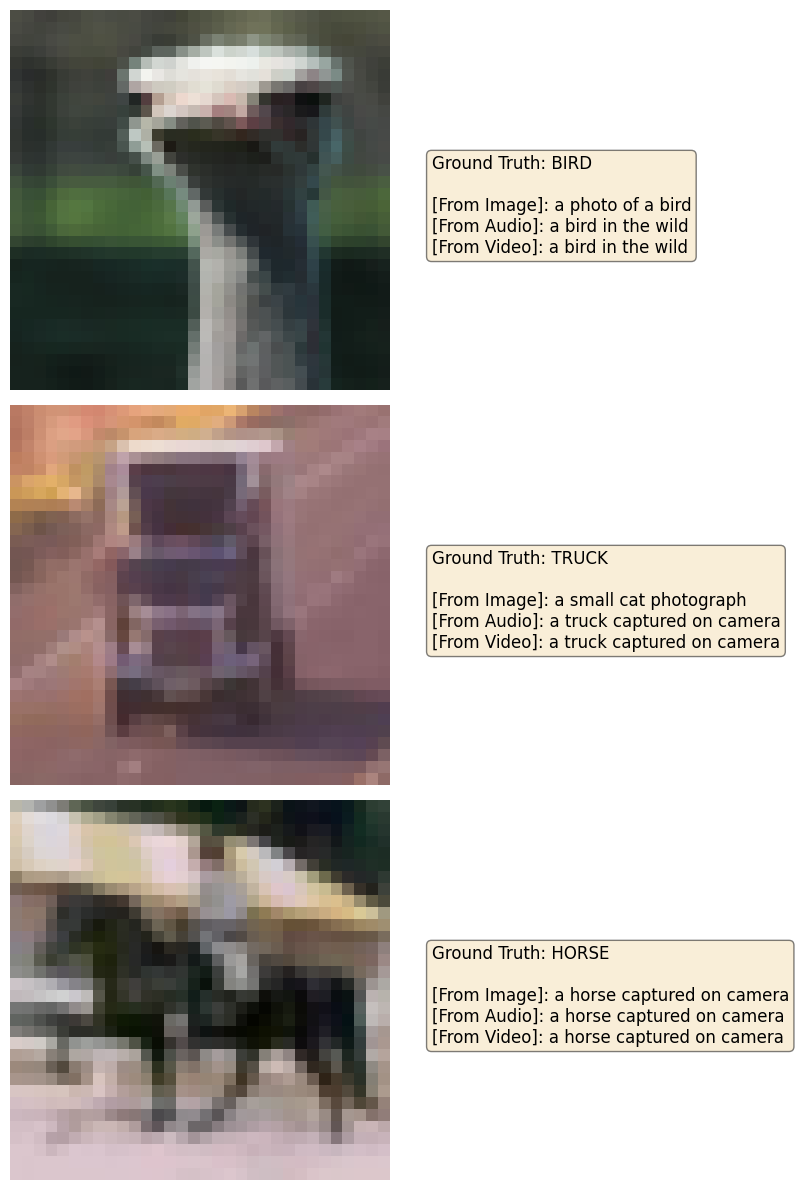

In [33]:
def visualize_text_gen(n_samples=3):
    indices = np.random.choice(len(test_dataset), n_samples, replace=False)
    fig, axes = plt.subplots(n_samples, 1, figsize=(10, 4 * n_samples))

    model.eval()
    with torch.no_grad():
        for i, idx in enumerate(indices):
            sample = test_dataset[idx]
            label = CLASS_NAMES[sample['label']]

            # Generate text from each source
            results = {}
            for mod in ['image', 'audio', 'video']:
                data = sample[mod].unsqueeze(0).to(DEVICE)
                _, _, z = model.encode(data, mod)
                tokens = model.text_decoder(z)
                results[mod] = indices_to_text(tokens[0].cpu().tolist())

            # Plotting
            ax = axes[i] if n_samples > 1 else axes
            img = denorm(sample['image']).permute(1, 2, 0).numpy()
            ax.imshow(img)
            ax.axis('off')

            info_text = (f"Ground Truth: {label.upper()}\n\n"
                         f"[From Image]: {results['image']}\n"
                         f"[From Audio]: {results['audio']}\n"
                         f"[From Video]: {results['video']}")

            ax.text(35, 16, info_text, fontsize=12, verticalalignment='center',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.tight_layout()
    plt.show()

visualize_text_gen(3)